<a href="https://colab.research.google.com/github/Budh05/Deep-Learning-/blob/main/Diffusion_Image_Generator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt       #to show visual representation
import torch                           #to build and train nural networks
import torch.nn as nn                  #crete layers
import torch.nn.functional as F

from torchvision import datasets, transforms
from torch.utils.data import DataLoader       #loading imgs in batches
print("Pytorch version:", torch.__version__)
print("GPU available", torch.cuda.is_available())

Pytorch version: 2.14.1+cu130
GPU available True


In [2]:
#loading data and normalize,normalizing bcz pixel vals range in 0-1 , we transform it into -1 - +1 making traininng more easy for our model
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])
train_data= datasets.MNIST(root="./data",train=True,download=True,transform=transform)

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.61MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 132kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.25MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.62MB/s]


In [3]:
train_loader= DataLoader(train_data,batch_size=128,shuffle=True)
print("Total imgs:",len(train_data))

Total imgs: 60000


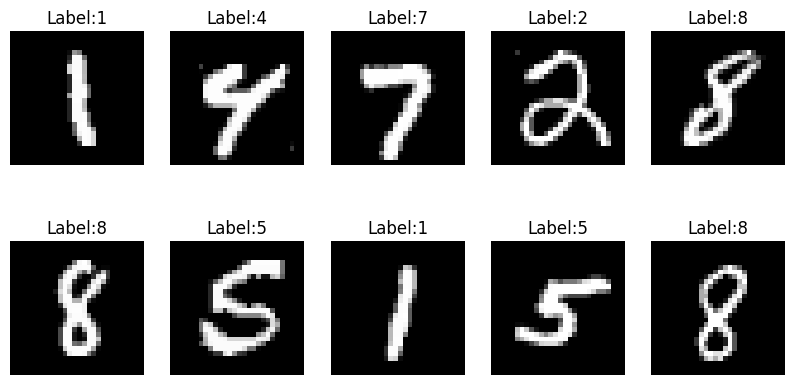

In [4]:
images,labels =next(iter(train_loader))
plt.figure(figsize=(10,5))

for i in range (10):
  plt.subplot(2,5,i+1)
  plt.imshow(images[i].squeeze(),cmap="gray")
  plt.title(f"Label:{labels[i].item()}")
  plt.axis("off")
plt.show()

***Noise and forward defussion***

**noise schedule**- decides how much noise to be added

**forward diffusion** - using svhedule to add noise to og img

we use 400 timesteps,and noise will bbe increased  1*10^-4 to 2*10^-2

In [5]:
T= 400

beta =torch.linspace(0.0001,0.02,T)
alpha= 1.0 -beta                      #alpah calcs remaining signals after each noise addition
alpha_bar= torch.cumprod(alpha,dim=0) #cals cumulative product of alpha val
print("Beta sahpe:",beta.shape)
print("alpha sahpe:",alpha.shape)
print("alpha_bar sahpe:",alpha_bar.shape)

Beta sahpe: torch.Size([400])
alpha sahpe: torch.Size([400])
alpha_bar sahpe: torch.Size([400])


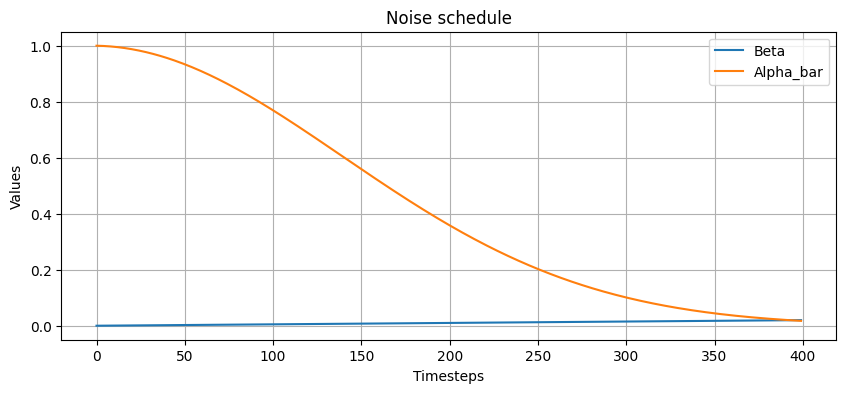

In [6]:
plt.figure(figsize=(10,4))
plt.plot(beta.numpy(),label="Beta")
plt.plot(alpha_bar.numpy(),label="Alpha_bar")
plt.xlabel("Timesteps")
plt.ylabel("Values")
plt.title("Noise schedule")
plt.legend()
plt.grid()
plt.show()

In [7]:
#implementing forward diffusion
def forward_diffusion(x_0,t):
  noise = torch.randn_like(x_0)   # generates random guassian noise with same sgape as og img
  sqrt_alpha_bar= torch.sqrt(alpha_bar[t])    #controls how much og innfo remains
  sqrt_one_minus_alpha_bar= torch.sqrt(1-alpha_bar[t]) #controls how musch noise is added
  xt= (sqrt_alpha_bar*x_0 + sqrt_one_minus_alpha_bar*noise) #combines og img and ranfom noise
  return xt,noise

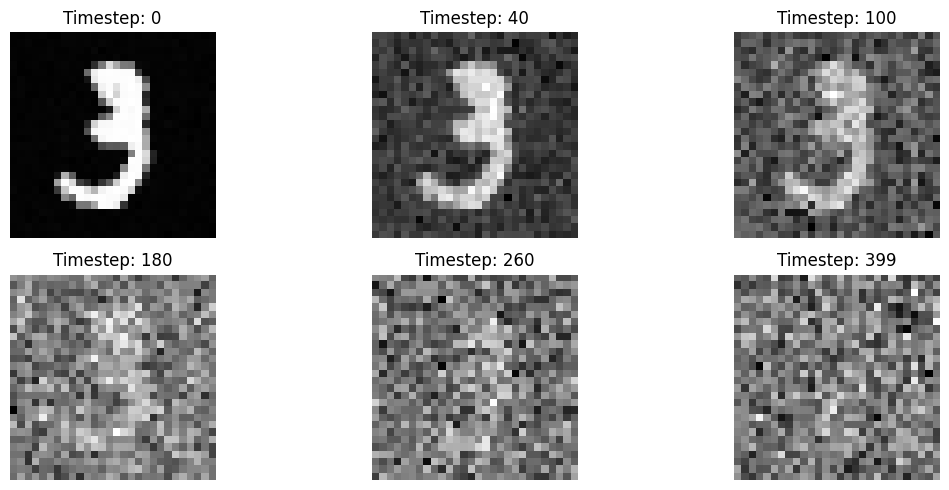

In [8]:
#visualising forward diffusion

image,label= train_data[10]

image= image.unsqueeze(0)
timesteps = [0, 40, 100, 180, 260, 399]
plt.figure(figsize=(12, 5))

for i, t in enumerate(timesteps):
    noisy_image, noise = forward_diffusion(
        image,
        t
    )
    plt.subplot(2, 3, i + 1)
    plt.imshow(
        noisy_image.squeeze(),
        cmap="gray")
    plt.title(f"Timestep: {t}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [9]:
#creating convolution block

class ConvBLock(nn.Module):
  def __init__(self,in_channels,out_channels):
    super().__init__()
    self.block = nn.Sequential(
        nn.Conv2d(in_channels,out_channels,kernel_size=3,padding=1),#extract img featurea
        nn.GroupNorm(8,out_channels),                                   #Normalize features
        nn.SiLU(),                                                   #Acti fn
        nn.Conv2d(out_channels,out_channels,kernel_size=3,padding=1),
        nn.GroupNorm(8,out_channels),
        nn.SiLU()
    )
  def forward(self,x):
    return self.block(x)

In [10]:
#building complete U Net
class UNet(nn.Module):
    def __init__(self):
        super().__init__()

        # Time embedding
        self.time_embedding = nn.Embedding(400, 128)
        self.time1 = nn.Linear(128, 32)
        self.time2 = nn.Linear(128, 64)
        self.time3 = nn.Linear(128, 64)

        # Encoder
        self.enc1 = ConvBLock(1, 32)
        self.down1 = nn.Conv2d(32, 64, 4, 2, 1)
        self.enc2 = ConvBLock(64, 64)
        self.down2 = nn.Conv2d(64, 64, 4, 2, 1)

        # Bottleneck
        self.middle = ConvBLock(64, 64)

        # Decoder
        self.up1 = nn.ConvTranspose2d(64, 64, 4, 2, 1)
        self.dec1 = ConvBLock(128, 64)
        self.up2 = nn.ConvTranspose2d(64, 32, 4, 2, 1)
        self.dec2 = ConvBLock(64, 32)

        # Output
        self.output = nn.Conv2d(32, 1, 1)

    def forward(self, x, t):
        # Time embedding
        temb = self.time_embedding(t)
        # Encoder
        e1 = self.enc1(x)
        e1 = e1 + self.time1(temb)[:, :, None, None]
        d1 = self.down1(e1)
        e2 = self.enc2(d1)
        e2 = e2 + self.time2(temb)[:, :, None, None]
        d2 = self.down2(e2)

        # Bottleneck
        mid = self.middle(d2)
        mid = mid + self.time3(temb)[:, :, None, None]

        # Decoder
        u1 = self.up1(mid)
        u1 = torch.cat([u1, e2], dim=1)
        u1 = self.dec1(u1)
        u2 = self.up2(u1)
        u2 = torch.cat([u2, e1], dim=1)
        u2 = self.dec2(u2)

        # Predicted noise
        return self.output(u2)

In [11]:
#testing unet working
model = UNet()
images, labels = next(iter(train_loader))
t = torch.randint(
    0, 400,(images.shape[0],))
predicted_noise = model(images, t)
print("Input shape:", images.shape)
print("Predicted noise shape:", predicted_noise.shape)

Input shape: torch.Size([128, 1, 28, 28])
Predicted noise shape: torch.Size([128, 1, 28, 28])


In [12]:
#training diffusion MOdel
#setting gpu from gooogle colab
device= torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device",device)
model=model.to(device)

Using device cuda


In [13]:
#making noise schedule for training
alpha_bar= alpha_bar.to(device)

In [14]:
def train_step(images):
    images = images.to(device)
    batch_size = images.shape[0]
                                  # Random timestep for every image
    t = torch.randint(0, T,(batch_size,),device=device)
                                  # Generate random noise
    noise = torch.randn_like(images)
                                  # Get alpha values for selected timesteps
    a_bar = alpha_bar[t].view(batch_size, 1, 1, 1)
                                  # Add noise to original images
    noisy_images = (torch.sqrt(a_bar) * images +torch.sqrt(1 - a_bar) * noise)

                                  # Predict noise using U-Net
    predicted_noise = model(noisy_images, t)

    # Calculate loss
    loss = F.mse_loss(predicted_noise, noise)

    return loss

In [15]:
#creating OPtimizer bit updates weights on basis of calc.ed loss
optmizer= torch.optim.Adam(model.parameters(),lr=0.001)
#here adam optimizr used , parameters tells adam whuch weights to update and lr = learning rate

In [16]:
#training loop
epochs = 5
loss_history = []
for epoch in range(epochs):
    total_loss = 0
    for images, labels in train_loader:
                                # Clear previous gradients
        optmizer.zero_grad()
                                # Calculate loss
        loss = train_step(images)
                                # Backpropagation
        loss.backward()
                                # Update weights
        optmizer.step()
        total_loss += loss.item()
    avg_loss = total_loss / len(train_loader)
    loss_history.append(avg_loss)
    print(
        f"Epoch [{epoch+1}/{epochs}], "
        f"Loss: {avg_loss:.4f}"
    )

Epoch [1/5], Loss: 0.0798
Epoch [2/5], Loss: 0.0482
Epoch [3/5], Loss: 0.0445
Epoch [4/5], Loss: 0.0424
Epoch [5/5], Loss: 0.0416


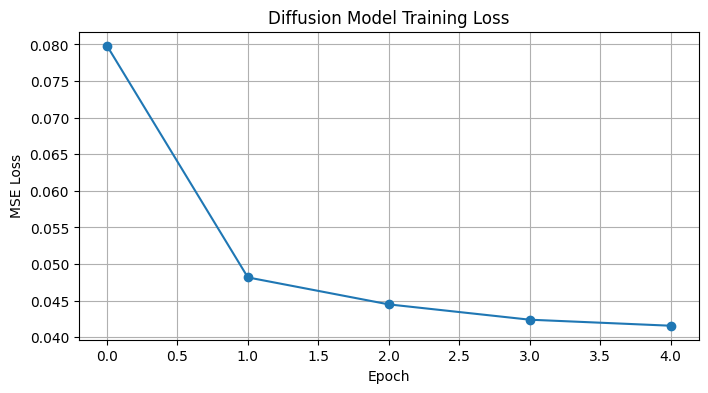

In [17]:
#visualzing training loss
plt.figure(figsize=(8, 4))
plt.plot(loss_history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Diffusion Model Training Loss")
plt.grid()
plt.show()

In [18]:
#Checking the loss values
print("Training Loss:", loss_history)

Training Loss: [0.07983136687801083, 0.048168758291806744, 0.04448331321385115, 0.04239128750047958, 0.04156779583646799]


In [19]:
#saving the model
torch.save(
    model.state_dict(),
    "diffusion_model.pth"
)

***Img  Generation by  Reverse Diffusion***